# Clio-Infra at historical borders — what is there

A survey of the DataverseNL deposits, the companion to `notebooks/clio`'s
`inventory.ipynb`: what is filed, how the workbooks are laid out, what their two
border schemes actually carry, what the working papers provide, and how the
stored series stand to the main site.

**Input**, all under `notebooks/clio_historical/data/` (gitignored):
`raw/<folder>/` — the deposits, downloaded by hand — plus `datasets.json` (every
indicator's DOI) and `documentation.yaml` (the working papers). **Output:**
`inventory.json`, written by `utils.inventory.build()` below. No network.

In [1]:
import sys
sys.path.append("../")          # notebooks/clio_historical/, for utils

import json
import numpy
import pandas
from matplotlib import pyplot, colors

from lib import config
from utils import accept, documentation, inventory

pyplot.style.use(config.glyfish_style)
pandas.set_option("display.max_rows", 100)
pandas.set_option("display.width", 160)

documentation.build()                     # the papers, in case more were filed
measured = inventory.build()
unfiled = json.loads((accept.DATA_DIR / inventory.INVENTORY).read_text())["unfiled"]
table = pandas.DataFrame([{"indicator": v["name"], "category": v["category"], **v}
                          for v in measured.values()]).drop(columns="name")
print(f"{len(measured)} of {len(measured) + len(unfiled)} indicators filed")

76 of 86 indicators filed


## What is filed

A zip download carries the working paper; a single-file download does not.

In [2]:
print(f"with a working paper : {table.paper.sum()}")
print(f"workbook only        : {(~table.paper).sum()}")
print(f"not filed            : {len(unfiled)}")
for name in unfiled:
    print(f"  {name}")

with a working paper : 52
workbook only        : 24
not filed            : 10
  Cattle per Capita
  Cropland per Capita
  Goats per Capita
  Number of Labour Disputes
  Pasture per Capita
  Pigs per Capita
  Regulation of Participation (PARREG)
  Sheep per Capita
  Total CO2 Emissions
  Total SO2 Emissions


## Three workbook layouts

The header row, `Webmapper code`, is the only thing they share. Above it sit a
title and a unit, a title alone (on a sheet called `Sheet1`), or nothing.

In [3]:
table.layout.value_counts().rename("indicators").to_frame()

,indicators
layout,
"title, unit, header",65
"title, header",10
header,1


## The two border schemes

The reason this source exists is its **GeaCron** rows — one per polity per
historical border period, holding the values inside that period. Its **CShapes**
rows are post-1946 states whose series reach back before 1946: the main site's
data in another layout, already stored as `clio`.

Every workbook lists the same ~1,412 GeaCron periods. Counting what they carry:

In [4]:
g = pandas.json_normalize(table.geacron.tolist()).add_prefix("geacron_")
c = pandas.json_normalize(table.cshapes.tolist()).add_prefix("cshapes_")
schemes = pandas.concat([table[["indicator", "category"]], g, c], axis=1)
print(f"GeaCron rows listed    : {schemes.geacron_rows.sum():,}")
print(f"  with any value       : {schemes.geacron_rows_with_values.sum():,}, "
      f"in {(schemes.geacron_rows_with_values > 0).sum()} indicators")
print(f"  observations         : {schemes.geacron_observations.sum():,}")
print(f"CShapes rows with value: {schemes.cshapes_rows_with_values.sum():,}")
print(f"  observations         : {schemes.cshapes_observations.sum():,}\n")
(schemes[schemes.geacron_rows_with_values > 0]
 [["indicator", "geacron_rows_with_values", "geacron_observations", "geacron_start", "geacron_end"]]
 .sort_values("geacron_observations", ascending=False).set_index("indicator"))

GeaCron rows listed    : 87,696
  with any value       : 418, in 5 indicators
  observations         : 11,378
CShapes rows with value: 9,306
  observations         : 821,599



,geacron_rows_with_values,geacron_observations,geacron_start,geacron_end
indicator,,,,
Exchange Rates to UK Pound,180,5685,1500.0,1945.0
Number of Days Lost in Labour Disputes,127,3423,1946.0,2012.0
Labourers Real Wage,102,2268,1820.0,1945.0
GDP per Capita,2,2,1870.0,1913.0
Working week in manufacturing,7,0,NaN,NaN


Four indicators, then, and GDP per capita only just. Working week's seven rows
carry no observations of their own: they are dependencies with no modern state
to file under — Bermuda, Gibraltar, Guam, Hong Kong, Polynesia, Puerto
Rico, Réunion — so their post-1946 values sit on a border period that ended in
1945. The builder drops values outside their row's period, as this count does.


Drawn by decade, the two schemes side by side on one scale. Each cell counts the
rows — states on the left, border periods on the right — with any value in that
decade. The right panel is the point: nearly empty.

Text(0.5, 0.98, 'DataverseNL deposits: what each border scheme carries')

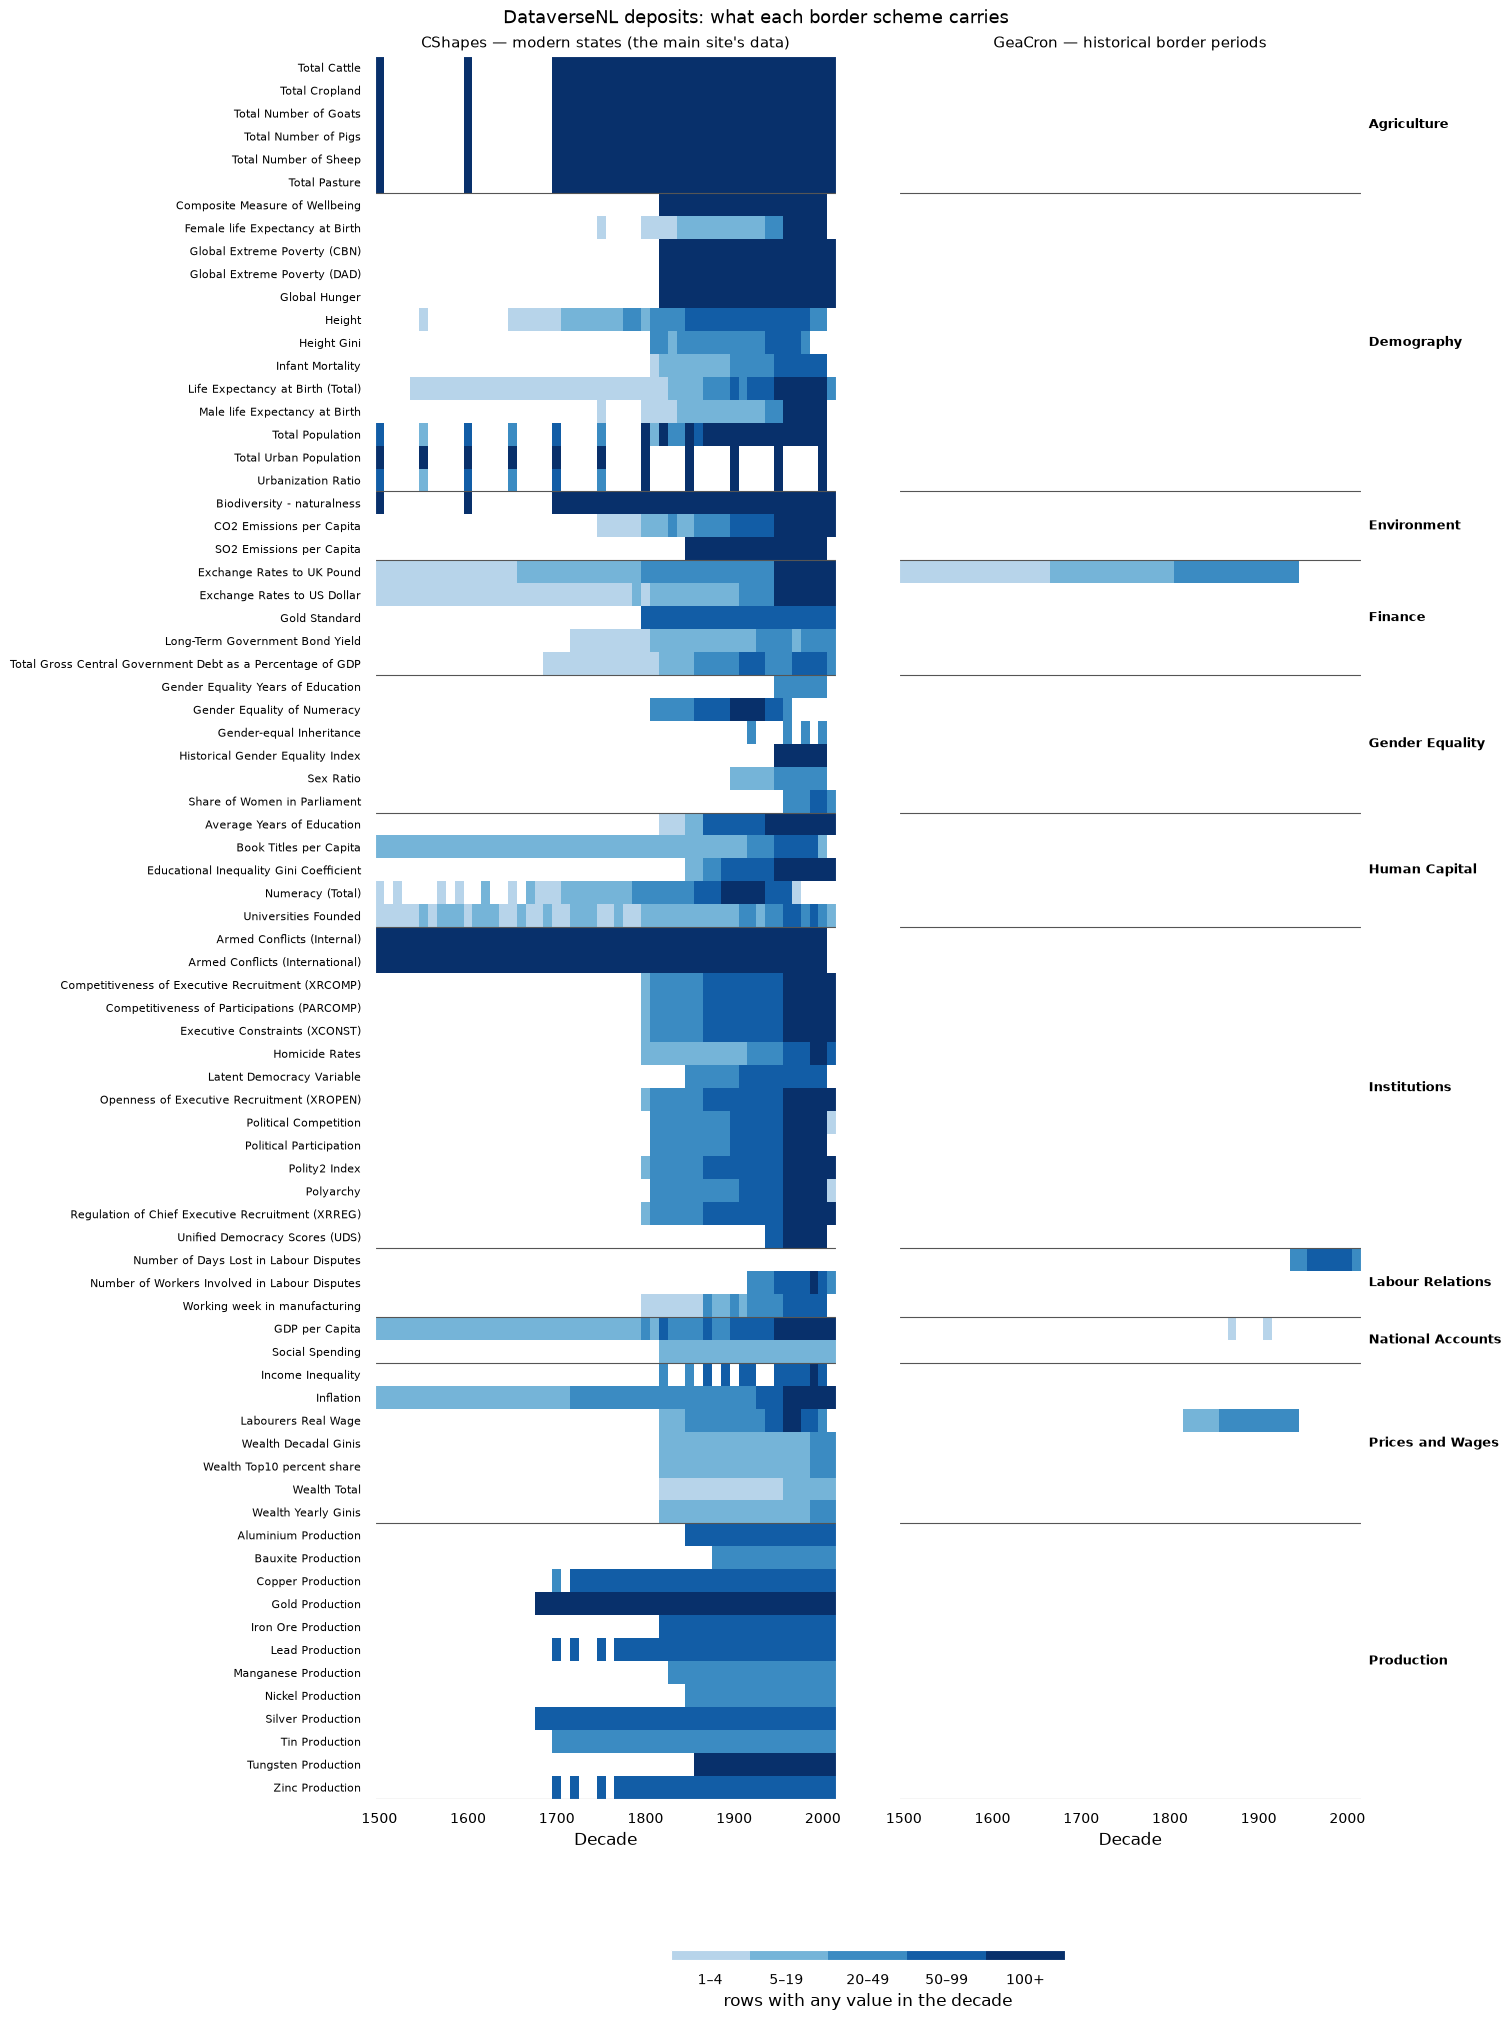

In [5]:
decades = numpy.arange(1500, 2020, 10)
rows = table.sort_values(["category", "indicator"]).reset_index(drop=True)

def grid(scheme):
    g = numpy.array([[measured[k][scheme]["rows_by_decade"].get(str(d), 0) for d in decades]
                     for k in (next(k for k, v in measured.items() if v["name"] == n) for n in rows.indicator)],
                    dtype=float)
    g[g == 0] = numpy.nan
    return g

bounds = [1, 5, 20, 50, 100, 250]
cmap = colors.ListedColormap(pyplot.get_cmap("Blues")(numpy.linspace(0.3, 1.0, len(bounds) - 1)))
cmap.set_bad("white")
norm = colors.BoundaryNorm(bounds, cmap.N)

figure, axes = pyplot.subplots(1, 2, figsize=(15, 20), sharey=True, layout="constrained")
figure.get_layout_engine().set(wspace=0.06)
for axis, scheme, title in ((axes[0], "cshapes", "CShapes — modern states (the main site's data)"),
                            (axes[1], "geacron", "GeaCron — historical border periods")):
    image = axis.pcolormesh(decades, numpy.arange(len(rows)), grid(scheme),
                            cmap=cmap, norm=norm, shading="nearest")
    axis.grid(False)
    axis.set_title(title, fontsize=11)
    axis.set_xlabel("Decade")
axes[0].set_yticks(numpy.arange(len(rows)))
axes[0].set_yticklabels(rows.indicator, fontsize=8)
axes[0].invert_yaxis()
start = 0
for category, group in rows.groupby("category", sort=False):
    end = start + len(group)
    for axis in axes:
        axis.axhline(end - 0.5, color="#555555", lw=0.8)
    axes[1].text(decades[-1] + 14, (start + end - 1) / 2, category, va="center",
                 fontsize=9, fontweight="bold")
    start = end
bar = figure.colorbar(image, ax=axes, orientation="horizontal", shrink=0.4, aspect=40,
                      ticks=[3, 12, 35, 75, 175])
bar.ax.set_xticklabels(["1–4", "5–19", "20–49", "50–99", "100+"])
bar.set_label("rows with any value in the decade")
figure.suptitle("DataverseNL deposits: what each border scheme carries", fontsize=13)

## What the working papers provide

The papers are where this source earns its keep: units, documentation, and a
data-quality grading the main site never states — when the paper fills it in.

In [6]:
papers = table[table.paper]
unit = numpy.where(table.workbook_unit.notna(), "workbook row 2",
                   numpy.where(table.paper_unit.notna(), "working paper", "none"))
print("unit comes from:")
print(pandas.Series(unit).value_counts().to_string(), "\n")
print(f"papers {len(papers)}: data quality assessed {papers.quality_stated.sum()}, "
      f"grades listed but none chosen {(~papers.quality_stated).sum()}")
print(f"  full working-paper text: {(papers.text_chars > 0).sum()}; "
      f"abstracts taken from Wikipedia: {(papers.abstract_source == 'wikipedia').sum()}; "
      f"superseded editions kept: {papers.superseded.sum()}")
print(f"  author's version: {papers.paper_version.value_counts(dropna=False).to_dict()}")

unit comes from:
workbook row 2    65
none               7
working paper      4 

papers 52: data quality assessed 29, grades listed but none chosen 23
  full working-paper text: 36; abstracts taken from Wikipedia: 4; superseded editions kept: 1
  author's version: {'1': 47, '2': 5}


## How the stored series stand to the main site

Every stored series was compared with the main site's, value by value, allowing
for the main site's rounding to seven significant figures.

In [7]:
stored = pandas.DataFrame([{"indicator": v["name"], **v["stored"]}
                           for v in measured.values() if v["stored"]]).fillna(0).set_index("indicator")
stored = stored.reindex(columns=["same", "successor", "differs", "new"], fill_value=0).astype(int)
stored.loc["total"] = stored.sum()
stored

,same,successor,differs,new
indicator,,,,
Exchange Rates to UK Pound,153,26,0,0
GDP per Capita,0,0,0,1
Labourers Real Wage,82,12,1,3
Number of Days Lost in Labour Disputes,117,0,0,0
total,352,38,1,4


Numerically, then, the deposits are the main site's data relabelled by the
borders in force: 352 series identical, 38 filed there under a modern successor,
one that differs because its borders do (the Netherlands with Belgium,
1820–39), and four the main site lacks. What this source adds is that label and,
more than the data, the working papers — whose units and documentation now feed
`clio`.